# Sales & Revenue Analysis Dashboard
**Internship Task 1 — Data Science / Business Analytics Domain**

**Goal:** Import sales data, clean it, visualize KPIs (total sales, revenue trends, top-performing products), and build a dashboard with charts and filters for interactive analysis.

**Dataset:** Synthetic order-level sales data for an online + retail store (1,210 orders across 5 categories, 4 regions, 3 sales channels, over calendar year 2025).


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
pd.set_option('display.max_columns', None)


## 2. Import the Data (CSV)

In [2]:
df = pd.read_csv('sales_raw_dataset.csv', parse_dates=['OrderDate'])
print("Shape:", df.shape)
df.head()


Shape: (1210, 11)


,OrderID,OrderDate,Category,Product,Region,SalesChannel,SalesRep,UnitPrice,Quantity,DiscountPct,Revenue
0,10849,2025-05-02,Beauty,Face Serum,East,Retail Store,Arjun,412.99,3,10,1115.06
1,10514,2025-01-21,Beauty,Shampoo,North,Retail Store,Arjun,270.93,3,10,731.50
2,10758,2025-04-02,Home & Kitchen,Blender,West,Online,Arjun,1033.80,3,0,3101.40
3,10522,2025-12-28,Home & Kitchen,Air Fryer,East,Online,Rahul,1679.83,4,10,6047.40
4,10931,2025-03-24,Beauty,Lipstick Set,North,Online,Sana,724.36,4,15,2462.82


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   OrderID       1210 non-null   int64         
 1   OrderDate     1210 non-null   datetime64[us]
 2   Category      1210 non-null   str           
 3   Product       1210 non-null   str           
 4   Region        1202 non-null   str           
 5   SalesChannel  1210 non-null   str           
 6   SalesRep      1195 non-null   str           
 7   UnitPrice     1210 non-null   float64       
 8   Quantity      1210 non-null   int64         
 9   DiscountPct   1210 non-null   int64         
 10  Revenue       1210 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(3), str(5)
memory usage: 104.1 KB


## 3. Data Cleaning

In [4]:
df.isnull().sum()


OrderID          0
OrderDate        0
Category         0
Product          0
Region           8
SalesChannel     0
SalesRep        15
UnitPrice        0
Quantity         0
DiscountPct      0
Revenue          0
dtype: int64

In [5]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()

df['SalesRep'] = df['SalesRep'].fillna('Unassigned')
df['Region'] = df['Region'].fillna('Unknown')

print("Shape after cleaning:", df.shape)
print("Missing values left:", df.isnull().sum().sum())


Duplicates before: 10
Shape after cleaning: (1200, 11)
Missing values left: 0


In [6]:
df['Month'] = df['OrderDate'].dt.to_period('M').astype(str)
df['Weekday'] = df['OrderDate'].dt.day_name()
df.head()


,OrderID,OrderDate,Category,Product,Region,SalesChannel,SalesRep,UnitPrice,Quantity,DiscountPct,Revenue,Month,Weekday
0,10849,2025-05-02,Beauty,Face Serum,East,Retail Store,Arjun,412.99,3,10,1115.06,2025-05,Friday
1,10514,2025-01-21,Beauty,Shampoo,North,Retail Store,Arjun,270.93,3,10,731.50,2025-01,Tuesday
2,10758,2025-04-02,Home & Kitchen,Blender,West,Online,Arjun,1033.80,3,0,3101.40,2025-04,Wednesday
3,10522,2025-12-28,Home & Kitchen,Air Fryer,East,Online,Rahul,1679.83,4,10,6047.40,2025-12,Sunday
4,10931,2025-03-24,Beauty,Lipstick Set,North,Online,Sana,724.36,4,15,2462.82,2025-03,Monday


## 4. Key Performance Indicators (KPIs)

In [7]:
total_revenue = df['Revenue'].sum()
total_orders = df['OrderID'].nunique()
total_units = df['Quantity'].sum()
avg_order_value = df['Revenue'].sum() / total_orders

print(f"Total Revenue:      Rs {total_revenue:,.0f}")
print(f"Total Orders:        {total_orders:,}")
print(f"Total Units Sold:    {total_units:,}")
print(f"Avg Order Value:    Rs {avg_order_value:,.0f}")


Total Revenue:      Rs 12,083,335
Total Orders:        1,200
Total Units Sold:    4,788
Avg Order Value:    Rs 10,069


## 5. Revenue Trend Over Time

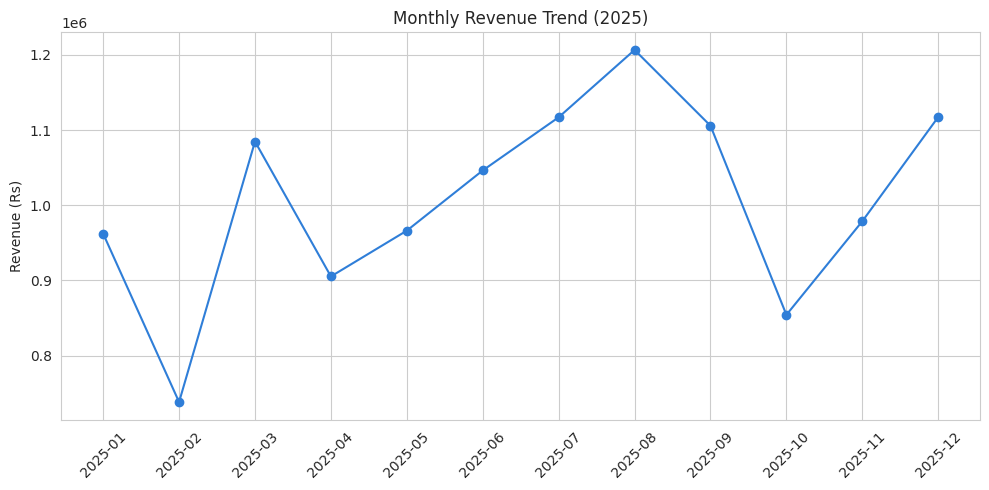

In [8]:
monthly = df.groupby('Month', as_index=False)['Revenue'].sum().sort_values('Month')

plt.figure(figsize=(10,5))
plt.plot(monthly['Month'], monthly['Revenue'], marker='o', color='#2f7ed8')
plt.title('Monthly Revenue Trend (2025)')
plt.ylabel('Revenue (Rs)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_trend.png', dpi=120)
plt.show()


## 6. Top-Performing Products

/tmp/ipykernel_118/4194371522.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products, y='Product', x='Revenue', palette='viridis')


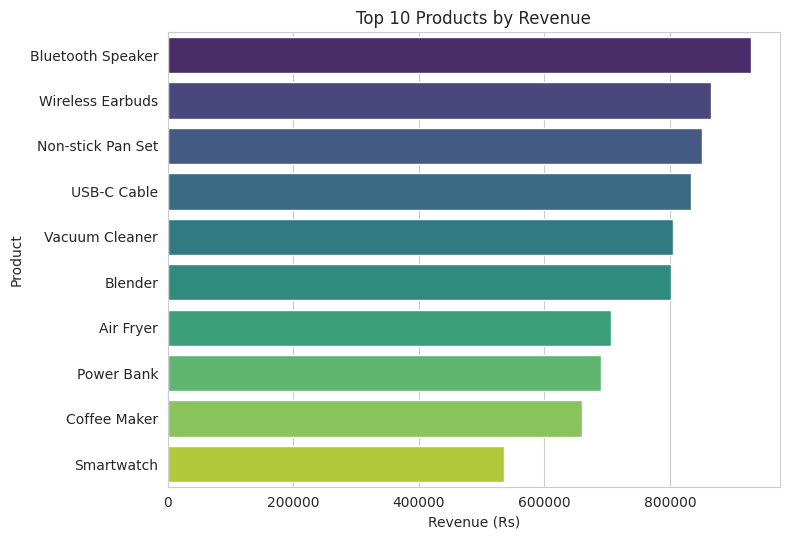

In [9]:
top_products = df.groupby('Product', as_index=False)['Revenue'].sum().sort_values('Revenue', ascending=False).head(10)

plt.figure(figsize=(8,5.5))
sns.barplot(data=top_products, y='Product', x='Revenue', palette='viridis')
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (Rs)')
plt.tight_layout()
plt.savefig('top_products.png', dpi=120)
plt.show()


## 7. Revenue by Category and Region

/tmp/ipykernel_118/3695787881.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_rev.index, y=cat_rev.values, ax=axes[0], palette='viridis')
/tmp/ipykernel_118/3695787881.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_rev.index, y=region_rev.values, ax=axes[1], palette='mako')


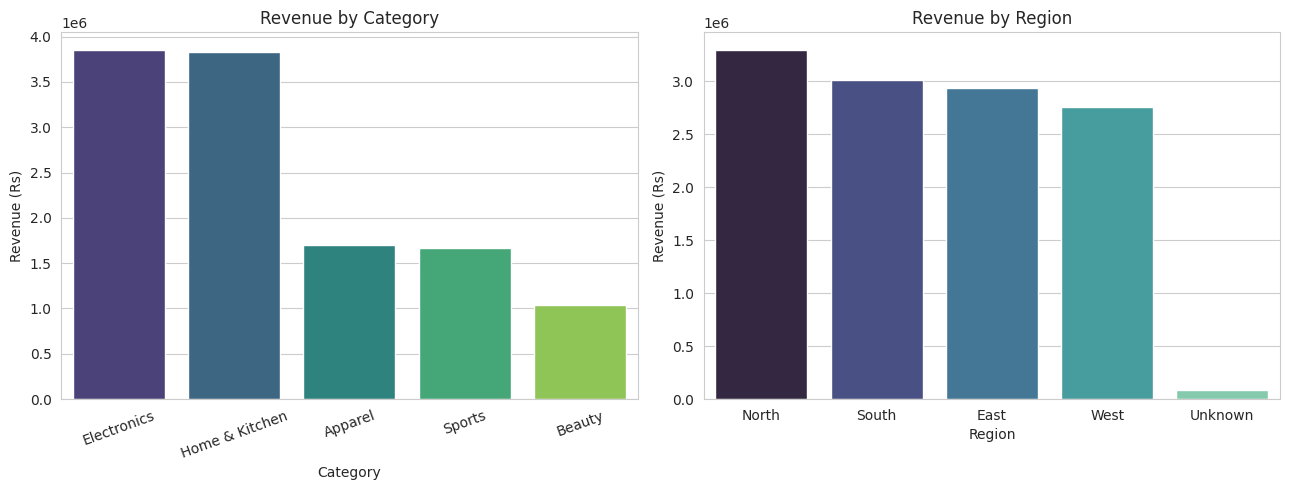

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
cat_rev = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.index, y=cat_rev.values, ax=axes[0], palette='viridis')
axes[0].set_title('Revenue by Category')
axes[0].set_ylabel('Revenue (Rs)')
axes[0].tick_params(axis='x', rotation=20)

region_rev = df.groupby('Region')['Revenue'].sum().sort_values(ascending=False)
sns.barplot(x=region_rev.index, y=region_rev.values, ax=axes[1], palette='mako')
axes[1].set_title('Revenue by Region')
axes[1].set_ylabel('Revenue (Rs)')
plt.tight_layout()
plt.savefig('revenue_by_category_region.png', dpi=120)
plt.show()


## 8. Sales Channel Mix

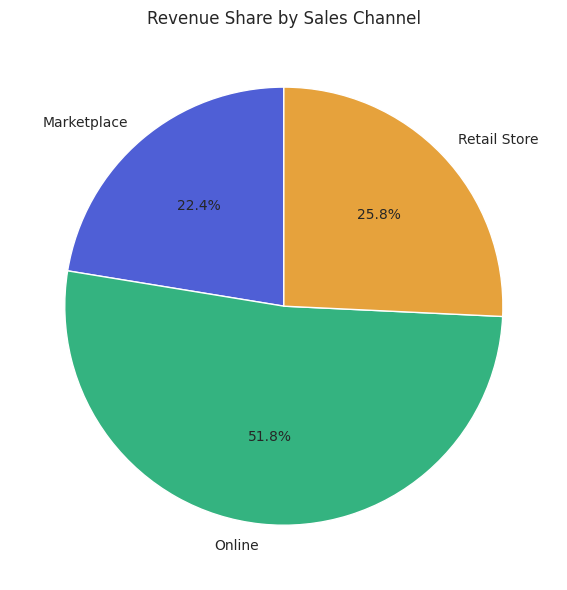

In [11]:
channel_rev = df.groupby('SalesChannel')['Revenue'].sum()
plt.figure(figsize=(6,6))
plt.pie(channel_rev, labels=channel_rev.index, autopct='%1.1f%%',
        colors=['#4f5fd6','#34b380','#e6a23c'], startangle=90)
plt.title('Revenue Share by Sales Channel')
plt.tight_layout()
plt.savefig('channel_mix.png', dpi=120)
plt.show()


## 9. Sales Rep Performance

/tmp/ipykernel_118/1579540601.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rep_perf, x='SalesRep', y='Revenue', palette='crest')


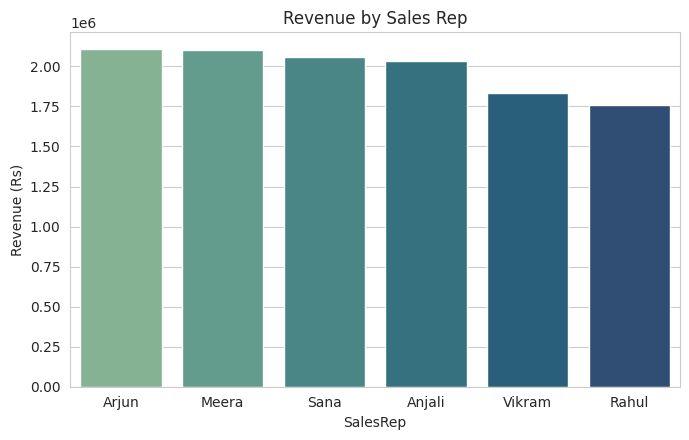

In [12]:
rep_perf = df[df['SalesRep'] != 'Unassigned'].groupby('SalesRep', as_index=False)['Revenue'].sum().sort_values('Revenue', ascending=False)
plt.figure(figsize=(7,4.5))
sns.barplot(data=rep_perf, x='SalesRep', y='Revenue', palette='crest')
plt.title('Revenue by Sales Rep')
plt.ylabel('Revenue (Rs)')
plt.tight_layout()
plt.savefig('rep_performance.png', dpi=120)
plt.show()


## 10. Discount Impact on Revenue

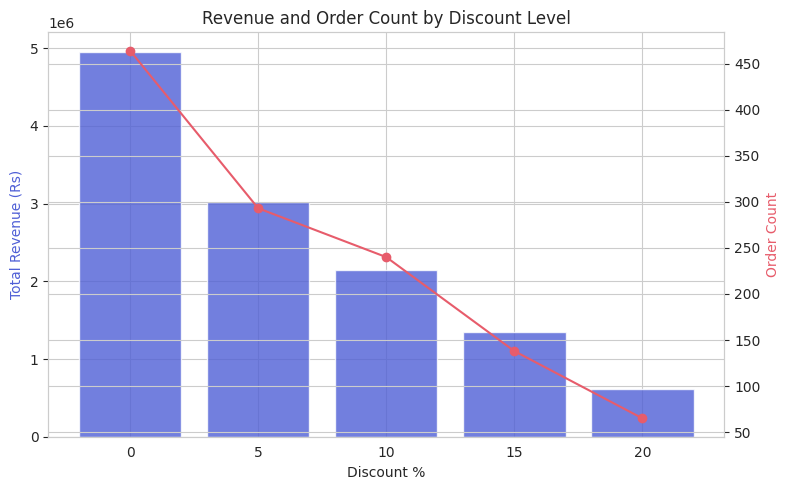

In [13]:
discount_rev = df.groupby('DiscountPct')['Revenue'].agg(TotalRevenue='sum', OrderCount='count').reset_index()

fig, ax1 = plt.subplots(figsize=(8,5))
ax1.bar(discount_rev['DiscountPct'].astype(str), discount_rev['TotalRevenue'], color='#4f5fd6', alpha=0.8)
ax1.set_ylabel('Total Revenue (Rs)', color='#4f5fd6')
ax1.set_xlabel('Discount %')
ax2 = ax1.twinx()
ax2.plot(discount_rev['DiscountPct'].astype(str), discount_rev['OrderCount'], color='#e75c6b', marker='o')
ax2.set_ylabel('Order Count', color='#e75c6b')
plt.title('Revenue and Order Count by Discount Level')
plt.tight_layout()
plt.savefig('discount_impact.png', dpi=120)
plt.show()


## 11. Combined Dashboard View

/tmp/ipykernel_118/1317259427.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products.head(6), y='Product', x='Revenue', palette='viridis', ax=axes[0,1])
/tmp/ipykernel_118/1317259427.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_rev.index, y=cat_rev.values, ax=axes[1,0], palette='viridis')


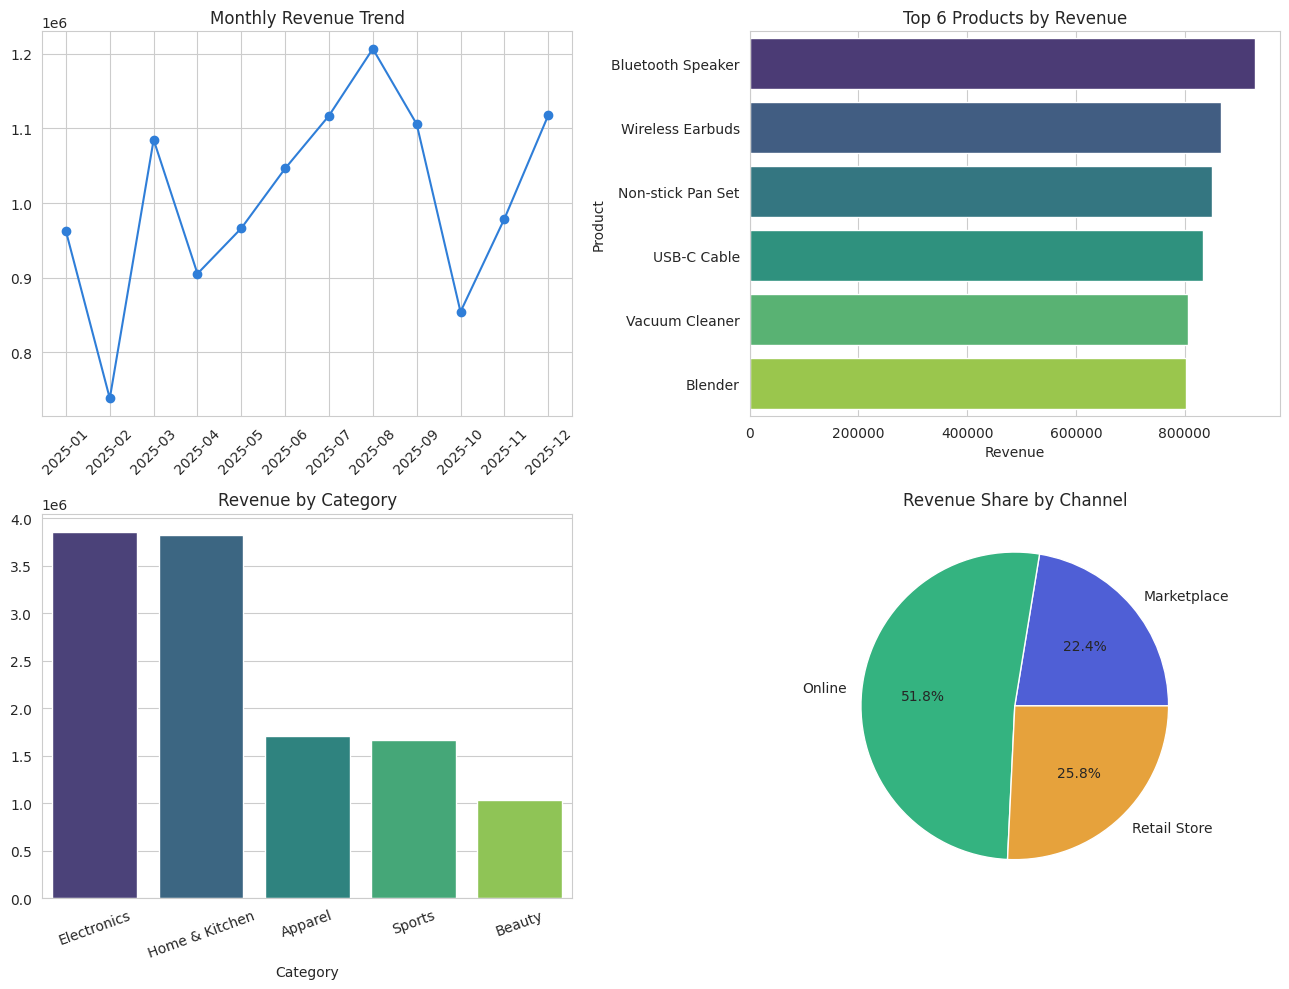

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0,0].plot(monthly['Month'], monthly['Revenue'], marker='o', color='#2f7ed8')
axes[0,0].set_title('Monthly Revenue Trend')
axes[0,0].tick_params(axis='x', rotation=45)

sns.barplot(data=top_products.head(6), y='Product', x='Revenue', palette='viridis', ax=axes[0,1])
axes[0,1].set_title('Top 6 Products by Revenue')

sns.barplot(x=cat_rev.index, y=cat_rev.values, ax=axes[1,0], palette='viridis')
axes[1,0].set_title('Revenue by Category')
axes[1,0].tick_params(axis='x', rotation=20)

axes[1,1].pie(channel_rev, labels=channel_rev.index, autopct='%1.1f%%', colors=['#4f5fd6','#34b380','#e6a23c'])
axes[1,1].set_title('Revenue Share by Channel')

plt.tight_layout()
plt.savefig('dashboard_summary.png', dpi=120)
plt.show()


## 12. Save the Cleaned Dataset

In [15]:
df.to_csv('sales_cleaned_dataset.csv', index=False)
print("Cleaned dataset saved. Final shape:", df.shape)


Cleaned dataset saved. Final shape: (1200, 13)


## 13. Key Business Insights

1. **Revenue shows month-to-month fluctuation across 2025** rather than a single dominant season — worth tracking against marketing campaigns or stock availability for each month.
2. **A small set of products drives a disproportionate share of revenue** (visible in the Top 10 Products chart) — a classic 80/20 pattern worth prioritizing in inventory and marketing.
3. **Category and region performance is uneven** — some categories and regions contribute far more revenue than others, which should inform where to focus sales effort.
4. **Online is the largest sales channel by revenue share**, followed by Retail Store and Marketplace — useful for channel investment decisions.
5. **Heavier discounts do not proportionally increase order volume** in this dataset — order counts don't scale up enough at high discount levels to offset the lower margin, suggesting discounting strategy is worth re-examining.

*(These insights are generated from a synthetic sample dataset — replace with your actual assigned dataset if one was provided, and re-run all cells top to bottom.)*
